In [1]:
!git clone https://github.com/chetana0904/songwriting-diffusion
!git pull

Cloning into 'songwriting-diffusion'...
remote: Enumerating objects: 550, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 550 (delta 1), reused 0 (delta 0), pack-reused 536 (from 1)
Receiving objects: 100% (550/550), 249.53 MiB | 28.39 MiB/s, done.
Resolving deltas: 100% (250/250), done.
fatal: not a git repository (or any parent up to mount point /kaggle)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).


In [3]:
data_dir = "/kaggle/input/datasets/haehyunlee/jamendo-songs-en"

In [5]:
cd /kaggle/working/songwriting-diffusion

/kaggle/working/songwriting-diffusion


In [28]:
%pip install -U "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 43.8 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.


In [8]:
!pip install -r requirements.txt
!pip install py3langid==0.2.2
!apt-get update -qq
!apt-get install -y espeak-ng libespeak-ng1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of gradio to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of gradio to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
INFO: pip is looking at multiple versions of torchvision to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of torchvision to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer t

In [11]:
import os, sys, json, math, glob, random
import numpy as np, pandas as pd, torch

REPO      = "/kaggle/working/songwriting-diffusion"
INPUT_DIR = "/kaggle/input/datasets/haehyunlee/jamendo-songs-en"
DATA_DIR  = "/kaggle/working/dataset_en"   # preprocessed latents / style / lrc tokens
OUT_DIR   = "/kaggle/working/lora_run"     # adapters, logs, plots

SEED = 42
SPLIT = {"train": 0.70, "val": 0.15, "test": 0.15}   # split BY SONG (no segment leakage)

# Data (dataset.py)
MAX_FRAMES = 2048          # DiffRhythm-1.2 base (~95 s)
MIN_FRAMES = 256           # repo default 512 (~23.8 s); lowered because short segments get dropped

# LoRA
LORA_RANK, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

# Optimisation
EPOCHS        = 10
BATCH_SIZE    = 1          # 1B DiT on a 16 GB T4
GRAD_ACCUM    = 4          # effective batch = BATCH_SIZE * GRAD_ACCUM
LR            = 2e-4
WARMUP_STEPS  = 10         # optimizer steps
MAX_GRAD_NORM = 1.0
GRAD_CKPT     = False      # set True if CUDA OOM

# CFG dropout during training (same as repo defaults)
AUDIO_DROP, STYLE_DROP, LRC_DROP = 0.3, 0.1, 0.1

# Deterministic evaluation: fixed timesteps x fixed noise seeds
EVAL_T       = [0.1, 0.3, 0.5, 0.7, 0.9]
EVAL_SEEDS   = 2
EVAL_TRAIN   = True        # also eval on train set each epoch (train-vs-val gap)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"            # fp16 autocast on GPU (T4 has no bf16)

os.makedirs(OUT_DIR, exist_ok=True)
os.chdir(REPO); sys.path.insert(0, REPO)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)
print(DEVICE, torch.cuda.get_device_name(0) if AMP else "")

cuda Tesla T4


In [15]:
!wget -q -O {REPO}/g2p/sources/chinese_lexicon.txt \
  https://raw.githubusercontent.com/ASLP-lab/DiffRhythm/main/g2p/sources/chinese_lexicon.txt

total 14460
drwxr-xr-x 3 root root     4096 Nov 24 09:27 .
drwxr-xr-x 6 root root     4096 Nov 24 09:14 ..
-rwxr-xr-x 1 root root      256 Nov 24 09:08 bpmf_2_pinyin.txt
-rw-r--r-- 1 root root 14779443 Nov 24 09:27 chinese_lexicon.txt
drwxr-xr-x 2 root root     4096 Nov 24 09:25 g2p_chinese_model
-rwxr-xr-x 1 root root     5262 Nov 24 09:08 pinyin_2_bpmf.txt


In [24]:
SONG_DIR = os.path.dirname(glob.glob(f"{INPUT_DIR}/**/*.lrc", recursive=True)[0])
print("songs from:", SONG_DIR, "|", len(glob.glob(f"{SONG_DIR}/*.lrc")), "lrc files")
!cd {REPO} && python preprocess/preprocess_data.py --input-dir "{SONG_DIR}" --output-dir "{DATA_DIR}"

songs from: /kaggle/input/datasets/haehyunlee/jamendo-songs-en | 47 lrc files
/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
./g2p/sources/g2p_chinese_model/poly_bert_model.onnx
/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(
Scanning /kaggle/input/datasets/haehyunlee/jamendo-songs-en for audio files...
Found 47 audio file(s) (47 with lyrics, 0 instrumental)
Will process 47 sample(s)
Loading VAE model (device=cuda)...
vae_model.pt: 100%|███████████████████████████| 625M/625M [00:04<00:00, 1

In [25]:
from dataset.dataset import DiffusionDataset

all_lines = [l.strip() for l in open(f"{DATA_DIR}/train.scp") if l.strip()]

# dataset.py silently replaces failing samples with random ones -> filter them out up front.
_probe = DiffusionDataset(f"{DATA_DIR}/train.scp", MAX_FRAMES, MIN_FRAMES, precision="fp32")
valid, dropped = [], []
for line in all_lines:
    try:
        _, _, latent, _ = _probe.get_triple(line)
        (valid if latent.shape[-1] >= MIN_FRAMES else dropped).append(line)
    except Exception:
        dropped.append(line)
print(f"valid {len(valid)} / {len(all_lines)} (dropped {len(dropped)})")

song_of = lambda line: line.split("|")[0].rsplit("_seg", 1)[0]
songs = sorted({song_of(l) for l in valid})
random.Random(SEED).shuffle(songs)
n_test = max(1, round(len(songs) * SPLIT["test"]))
n_val  = max(1, round(len(songs) * SPLIT["val"]))
split_songs = {"test": songs[:n_test], "val": songs[n_test:n_test + n_val],
               "train": songs[n_test + n_val:]}

SCP = {}
for name, ss in split_songs.items():
    lines = [l for l in valid if song_of(l) in set(ss)]
    SCP[name] = f"{OUT_DIR}/{name}.scp"
    open(SCP[name], "w").write("\n".join(lines) + "\n")
    print(f"{name:5s}: {len(ss):2d} songs, {len(lines):3d} segments")
json.dump(split_songs, open(f"{OUT_DIR}/split.json", "w"), indent=2)

valid 47 / 47 (dropped 0)
test :  3 songs,   6 segments
val  :  3 songs,   7 segments
train: 14 songs,  34 segments


In [29]:
from huggingface_hub import hf_hub_download
from peft import LoraConfig, get_peft_model
from model import CFM, DiT

model_cfg = json.load(open(f"{REPO}/config/diffrhythm-1b.json"))
cfm_kwargs = dict(num_channels=model_cfg["model"]["mel_dim"], audio_drop_prob=AUDIO_DROP,
                  cond_drop_prob=0.0, style_drop_prob=STYLE_DROP, lrc_drop_prob=LRC_DROP,
                  max_frames=MAX_FRAMES)

def load_pretrained_dit():
    cfm = CFM(transformer=DiT(**model_cfg["model"], max_frames=MAX_FRAMES), **cfm_kwargs)
    ckpt = torch.load(hf_hub_download("ASLP-lab/DiffRhythm-1_2", "cfm_model.pt",
                                      cache_dir=f"{REPO}/pretrained"),
                      map_location="cpu", weights_only=True)
    sd = ckpt.get("model_state_dict", ckpt)
    if "ema_model_state_dict" in ckpt:
        sd = {k.replace("ema_model.", ""): v for k, v in ckpt["ema_model_state_dict"].items()
              if k not in ("initted", "step")}
    missing, unexpected = cfm.load_state_dict(sd, strict=False)
    print(f"pretrained loaded | missing {len(missing)} | unexpected {len(unexpected)}")
    return cfm.transformer

dit = get_peft_model(load_pretrained_dit(), LoraConfig(
    r=LORA_RANK, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGETS, bias="none"))
dit.print_trainable_parameters()

if GRAD_CKPT:  # activation checkpointing per transformer block
    from torch.utils.checkpoint import checkpoint
    for blk in dit.base_model.model.transformer_blocks:
        blk._fwd = blk.forward
        blk.forward = lambda *a, _b=blk, **k: checkpoint(_b._fwd, *a, use_reentrant=False, **k)

model = CFM(transformer=dit, **cfm_kwargs).to(DEVICE)

pretrained loaded | missing 0 | unexpected 0
trainable params: 12,058,624 || all params: 1,121,374,272 || trainable%: 1.0753


In [32]:
import torch.nn.functional as F
from torch.utils.data import DataLoader
from model.utils import lens_to_mask

def make_loader(scp, shuffle):
    ds = DiffusionDataset(scp, MAX_FRAMES, MIN_FRAMES, precision="fp32")
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2,
                      collate_fn=ds.custom_collate_fn, drop_last=False)

train_dl = make_loader(SCP["train"], True)
eval_dl  = {k: make_loader(SCP[k], False) for k in ("train", "val", "test")}

def to_dev(batch):
    return dict(x1=batch["latent"].permute(0, 2, 1).to(DEVICE).float(),   # [b, n, 64]
                lens=batch["latent_lengths"].to(DEVICE),
                text=batch["lrc"].to(DEVICE),
                style=batch["prompt"].to(DEVICE).float(),
                start=batch["start_time"].to(DEVICE).float())

@torch.no_grad()
def evaluate(dl, t_vals=EVAL_T, n_seeds=EVAL_SEEDS):
    """
    Flow-matching MSE with FIXED t and FIXED noise (no CFG dropout), so the number is
    comparable across epochs. Same objective as CFM.forward:
        x_t = (1-t) x0 + t x1,  target v = x1 - x0,  loss = MSE(v_pred, v) on valid frames
    """
    model.eval()
    per_t = {t: [] for t in t_vals}
    for bi, batch in enumerate(dl):
        b = to_dev(batch)
        x1 = b["x1"]
        mask = lens_to_mask(b["lens"], length=x1.shape[1])
        cond = torch.zeros_like(x1)
        for s in range(n_seeds):
            g = torch.Generator(device=DEVICE).manual_seed(10_000 * bi + s)
            x0 = torch.randn(x1.shape, generator=g, device=DEVICE)
            for t in t_vals:
                tt = torch.full((x1.shape[0],), t, device=DEVICE)
                with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
                    pred = model.transformer(x=(1 - t) * x0 + t * x1, cond=cond, text=b["text"],
                                             time=tt, drop_audio_cond=False, drop_text=False,
                                             drop_prompt=False, style_prompt=b["style"],
                                             start_time=b["start"])
                per_t[t].append(F.mse_loss(pred.float(), x1 - x0, reduction="none")[mask].mean().item())
    out = {f"loss_t{t}": float(np.mean(v)) for t, v in per_t.items()}
    out["loss"] = float(np.mean(list(out.values())))
    return out

In [33]:
from tqdm.auto import tqdm

params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
steps_per_epoch = math.ceil(len(train_dl) / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
def lr_lambda(step):  # linear warmup -> cosine decay to 5% of LR
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, total_steps - WARMUP_STEPS)
    return 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * min(1.0, p)))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)

step_log, epoch_log = [], []
best_val = float("inf")

def log_epoch(epoch, train_loss):
    global best_val
    row = {"epoch": epoch, "train_loss": train_loss}
    if EVAL_TRAIN:
        row.update({f"train_eval_{k}": v for k, v in evaluate(eval_dl["train"]).items()})
    row.update({f"val_{k}": v for k, v in evaluate(eval_dl["val"]).items()})
    if row["val_loss"] < best_val:
        best_val = row["val_loss"]
        model.transformer.save_pretrained(f"{OUT_DIR}/lora_best")
        row["best"] = True
    epoch_log.append(row)
    pd.DataFrame(epoch_log).to_csv(f"{OUT_DIR}/epoch_log.csv", index=False)
    pd.DataFrame(step_log).to_csv(f"{OUT_DIR}/step_log.csv", index=False)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()
           if k in ("epoch", "train_loss", "train_eval_loss", "val_loss", "best")})

# epoch 0 = pretrained baseline (LoRA B matrices start at zero -> identical to base model)
log_epoch(0, float("nan"))

global_step = 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    losses, accum = [], []
    pbar = tqdm(train_dl, desc=f"epoch {epoch}/{EPOCHS}")
    for i, batch in enumerate(pbar):
        b = to_dev(batch)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            loss, _, _ = model(b["x1"], text=b["text"], lens=b["lens"], style_prompt=b["style"],
                               start_time=b["start"])
        scaler.scale(loss / GRAD_ACCUM).backward()
        accum.append(loss.item()); losses.append(loss.item())

        if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(train_dl):
            scaler.unscale_(opt)
            gnorm = torch.nn.utils.clip_grad_norm_(params, MAX_GRAD_NORM).item()
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            global_step += 1
            step_log.append({"step": global_step, "epoch": epoch, "loss": float(np.mean(accum)),
                             "lr": sched.get_last_lr()[0], "grad_norm": gnorm})
            sched.step(); accum = []
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    log_epoch(epoch, float(np.mean(losses)))

model.transformer.save_pretrained(f"{OUT_DIR}/lora_last")
print("best val loss:", best_val)

{'epoch': 0, 'train_loss': nan, 'train_eval_loss': 0.9925, 'val_loss': 1.0062, 'best': True}


epoch 1/10:   0%|          | 0/34 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.9797, 'train_eval_loss': 0.989, 'val_loss': 1.002, 'best': True}


epoch 2/10:   0%|          | 0/34 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.9694, 'train_eval_loss': 0.9817, 'val_loss': 0.9933, 'best': True}


epoch 3/10:   0%|          | 0/34 [00:00<?, ?it/s]

... (11 outputs left out)

epoch 9/10:   0%|          | 0/34 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.9672, 'train_eval_loss': 0.9753, 'val_loss': 0.9901, 'best': True}


epoch 10/10:   0%|          | 0/34 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.9335, 'train_eval_loss': 0.9752, 'val_loss': 0.99, 'best': True}
best val loss: 0.9900424386773791


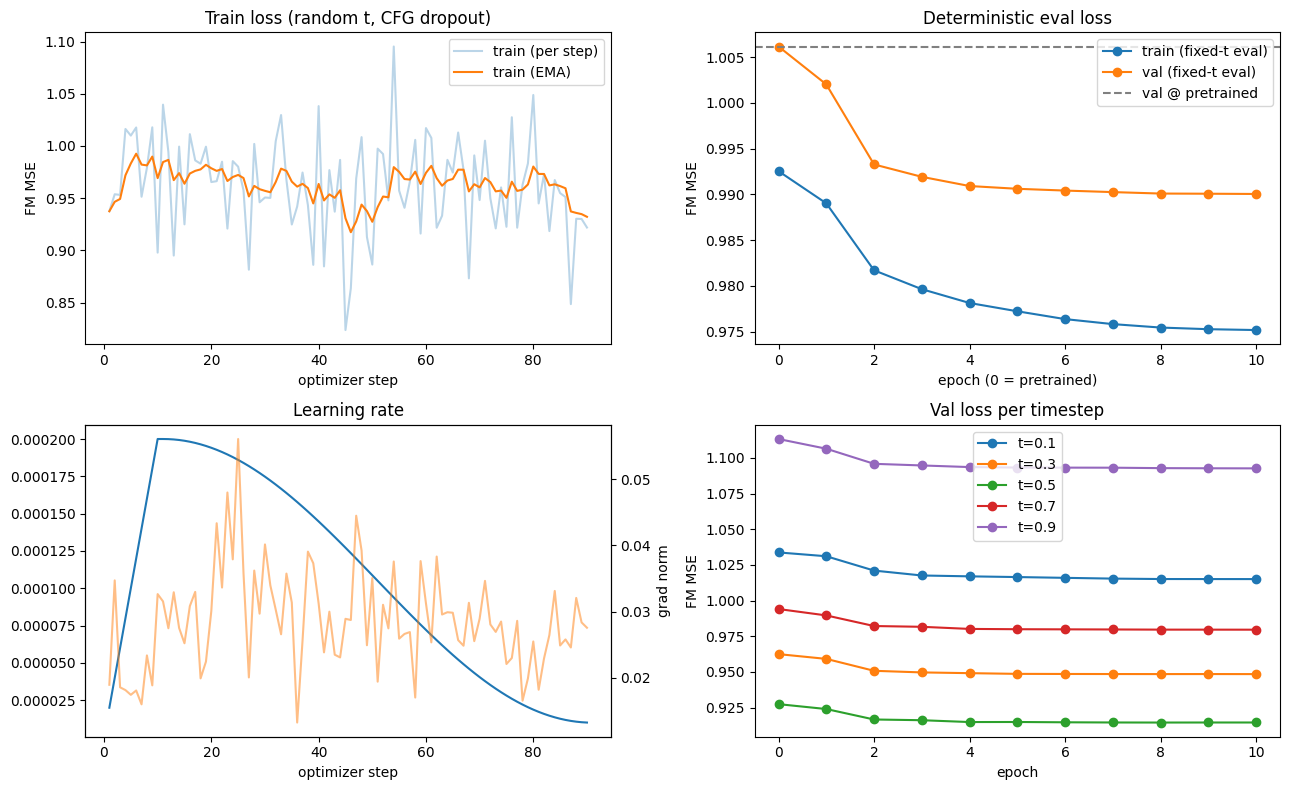

In [34]:
import matplotlib.pyplot as plt

sl, el = pd.read_csv(f"{OUT_DIR}/step_log.csv"), pd.read_csv(f"{OUT_DIR}/epoch_log.csv")
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

a = ax[0, 0]
a.plot(sl.step, sl.loss, alpha=0.3, label="train (per step)")
a.plot(sl.step, sl.loss.ewm(alpha=0.2).mean(), label="train (EMA)")
a.set(title="Train loss (random t, CFG dropout)", xlabel="optimizer step", ylabel="FM MSE"); a.legend()

a = ax[0, 1]
if "train_eval_loss" in el:
    a.plot(el.epoch, el.train_eval_loss, "o-", label="train (fixed-t eval)")
a.plot(el.epoch, el.val_loss, "o-", label="val (fixed-t eval)")
a.axhline(el.val_loss.iloc[0], ls="--", c="gray", label="val @ pretrained")
a.set(title="Deterministic eval loss", xlabel="epoch (0 = pretrained)", ylabel="FM MSE"); a.legend()

a = ax[1, 0]
a.plot(sl.step, sl.lr); a.set(title="Learning rate", xlabel="optimizer step")
a2 = a.twinx(); a2.plot(sl.step, sl.grad_norm, c="tab:orange", alpha=0.5); a2.set_ylabel("grad norm")

a = ax[1, 1]
for t in EVAL_T:
    a.plot(el.epoch, el[f"val_loss_t{t}"], "o-", label=f"t={t}")
a.set(title="Val loss per timestep", xlabel="epoch", ylabel="FM MSE"); a.legend()

plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=120); plt.show()

           pretrained  lora_best  rel_change_%
loss_t0.1      1.0364     1.0189       -1.6903
loss_t0.3      0.9214     0.9122       -0.9974
loss_t0.5      0.8744     0.8659       -0.9703
loss_t0.7      0.9455     0.9367       -0.9241
loss_t0.9      1.0855     1.0737       -1.0953
loss           0.9726     0.9615       -1.1478


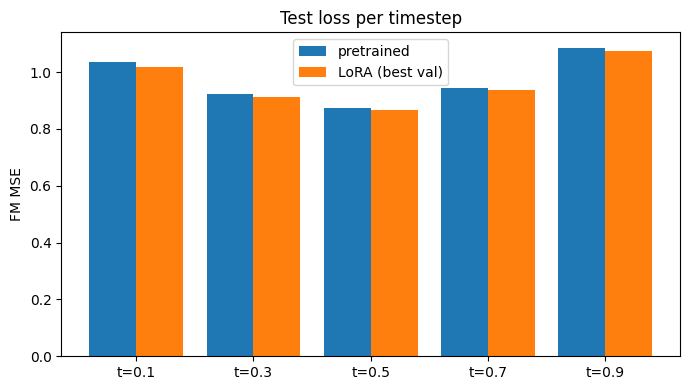

In [35]:
from peft import set_peft_model_state_dict
from safetensors.torch import load_file

set_peft_model_state_dict(model.transformer,
                          load_file(f"{OUT_DIR}/lora_best/adapter_model.safetensors"))
test_lora = evaluate(eval_dl["test"])
with model.transformer.disable_adapter():
    test_base = evaluate(eval_dl["test"])

res = pd.DataFrame({"pretrained": test_base, "lora_best": test_lora})
res["rel_change_%"] = 100 * (res.lora_best - res.pretrained) / res.pretrained
res.to_csv(f"{OUT_DIR}/test_results.csv"); print(res.round(4))

ts = [f"loss_t{t}" for t in EVAL_T]
x = np.arange(len(EVAL_T))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, res.loc[ts, "pretrained"], 0.4, label="pretrained")
plt.bar(x + 0.2, res.loc[ts, "lora_best"], 0.4, label="LoRA (best val)")
plt.xticks(x, [f"t={t}" for t in EVAL_T]); plt.ylabel("FM MSE"); plt.title("Test loss per timestep")
plt.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/test_loss.png", dpi=120); plt.show()

In [36]:
!cd /kaggle/working && zip -r lora_run.zip lora_run

  adding: lora_run/ (stored 0%)
  adding: lora_run/test.scp (deflated 86%)
  adding: lora_run/step_log.csv (deflated 52%)
  adding: lora_run/epoch_log.csv (deflated 54%)
  adding: lora_run/lora_last/ (stored 0%)
  adding: lora_run/lora_last/adapter_config.json (deflated 62%)
  adding: lora_run/lora_last/README.md (deflated 66%)
  adding: lora_run/lora_last/adapter_model.safetensors (deflated 7%)
  adding: lora_run/test_loss.png (deflated 19%)
  adding: lora_run/val.scp (deflated 87%)
  adding: lora_run/split.json (deflated 41%)
  adding: lora_run/training_curves.png (deflated 6%)
  adding: lora_run/train.scp (deflated 91%)
  adding: lora_run/lora_best/ (stored 0%)
  adding: lora_run/lora_best/adapter_config.json (deflated 62%)
  adding: lora_run/lora_best/README.md (deflated 66%)
  adding: lora_run/lora_best/adapter_model.safetensors (deflated 7%)
  adding: lora_run/test_results.csv (deflated 43%)
